Specificity of this file:
We will train on quotes, test on trades, for both prices and implied vol.
Rolling window to post match trade.

Cleaned to use functions defined in another file.

In [1]:
import os
import sys
from datetime import date, datetime

# import torch
# from torch.func import jacrev
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import polars as pl
import pytz

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

import black_scholes
import ekf
import events
import plots
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

from quantdata.massive.client import MassiveClient

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:152: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


## DATA LOADING

In [2]:
option_ticker = "O:SPY240105P00470000"

In [3]:
client = MassiveClient()
df_quotes = client.fetch_quotes(option_ticker, date(2024, 1, 3))

In [4]:
df_trades = client.fetch_trades(option_ticker, date(2024, 1, 3))

In [5]:
df_spy = client.fetch_trades("SPY", date(2024, 1, 3))

In [6]:
df_trades = events.filter_df(df_trades)
df_spy = events.filter_df(df_spy)

# Merging with time Lag

In [7]:
# df_combined = events.match_trade_to_closest_quote(df_trades=df_trades, df_quotes=df_quotes)

In [8]:
df_events = events.build_event_stream(df_quotes, df_trades)

In [9]:
# df_events = df_events.drop_nans()

# TRAIN

In [10]:
# ── STEP 1: Train the Kalman filter on quotes only ───────────────────────────
df_quotes_only = df_events.filter(pl.col("event_type") == "quote")

prices_train = jnp.array(df_quotes_only["observed_price"].to_numpy(), dtype=jnp.float32)
Rs_train = jnp.array(df_quotes_only["R"].to_numpy(), dtype=jnp.float32)

estimates_train = ekf.run_ekf(prices_train, Rs_train)

df_quotes_result = df_quotes_only.with_columns(
    pl.Series("kalman_price", jax.device_get(estimates_train).tolist())
)

# ── STEP 2: Test on trades ────────────────────────────────────────────────────
# For each trade, get the Kalman estimate from the most recent preceding quote.
# This is a pure out-of-sample evaluation: the filter never saw trades.

df_trades_only = df_events.filter(pl.col("event_type") == "trade")

df_trades_result = df_trades_only.join_asof(
    df_quotes_result.select(["ts_ns", "kalman_price"]).rename({"kalman_price": "kalman_prior"}),
    on="ts_ns",
    strategy="backward",
)

# Residual: how far is the trade price from the filter's quote-derived estimate?
df_trades_result = df_trades_result.with_columns(
    (pl.col("observed_price") - pl.col("kalman_prior")).alias("trade_residual")
)

In [11]:
# plt.plot(df_trades_result["ts_ns"], df_trades_result["trade_residual"])
# plots.scatter_residual_vs_lag(df_trades_result)
# plots.plot_residual_vs_lag(df_trades_result)

df_trades_result.select((pl.col("trade_residual") ** 2).mean())

trade_residual
f64
0.000092


## NOW IMPLIED VOL

In [12]:
df_events = df_events.join_asof(
    df_spy.select(["ts_ns", "price"]), on="ts_ns", strategy="backward"
).rename({"price": "spot"})

In [13]:
# Expiry: next day at 16:00 ET (standard US equity options close)
expiry = datetime(2024, 1, 4, 16, 0, 0, tzinfo=pytz.timezone("America/New_York"))

df_events = df_events.with_columns(
    ((pl.lit(expiry) - pl.col("ts_ns")).dt.total_nanoseconds() / (365.25 * 24 * 3600 * 1e9)).alias(
        "T"
    )
)

In [14]:
# Extract as JAX arrays (zero-copy via numpy)
price = jnp.array(df_events["observed_price"].to_numpy())
S = jnp.array(df_events["spot"].to_numpy())
K = jnp.full_like(price, 470.0)  # hardcoded strike for this contract
T = jnp.array(df_events["T"].to_numpy())  # time to expiry in years
r = jnp.full_like(price, 0.0)  # assume 0 for intraday changes

iv = black_scholes.newton_iv(price, S, K, T, r)

# Write back
df_events = df_events.with_columns(pl.Series("iv", iv.tolist()))

In [15]:
bid_price = jnp.array(df_events["bid_price"].to_numpy())
ask_price = jnp.array(df_events["ask_price"].to_numpy())
bid_iv = black_scholes.newton_iv(bid_price, S, K, T, r)
ask_iv = black_scholes.newton_iv(ask_price, S, K, T, r)
df_events = df_events.with_columns(
    [
        pl.Series("bid_iv", bid_iv.tolist()),
        pl.Series("ask_iv", ask_iv.tolist()),
    ]
)

In [16]:
df_events = events.events_to_iv(df_events)

## KF on IV

In [17]:
df_iv_quotes_only = df_events.filter(pl.col("event_type") == "quote")
df_iv_quotes_only

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,matched_lag_ns,spot,T,observed_iv,bid_iv,ask_iv,R_iv
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0,470.45,0.003479,0.135038,0.133215,0.136859,0.03319
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0.000018,0,470.45,0.003479,0.135038,0.134127,0.135948,0.008293
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0,470.46,0.003479,0.134535,0.132715,0.136359,0.033199
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0.000649,0,470.46,0.003479,0.131422,0.130897,0.140908,0.250582
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0.000733,0,470.46,0.003479,0.137236,0.129072,0.140908,0.350229
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0.000016,0,468.74,0.00271,0.301807,0.301316,0.303399,0.010855
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0.000017,0,468.74,0.00271,0.301952,0.301314,0.303398,0.010853
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0.000018,0,468.74,0.00271,0.303834,0.302378,0.30446,0.010847


In [18]:
# ── STEP 1: Train the Kalman filter on quotes only ───────────────────────────
df_iv_quotes_only = df_events.filter(pl.col("event_type") == "quote")

prices_train = jnp.array(df_iv_quotes_only["observed_iv"].to_numpy(), dtype=jnp.float32)
Rs_train = jnp.array(df_iv_quotes_only["R_iv"].to_numpy(), dtype=jnp.float32)

estimates_train = ekf.run_ekf(prices_train, Rs_train)

df_iv_quotes_result = df_iv_quotes_only.with_columns(
    pl.Series("kalman_iv", jax.device_get(estimates_train).tolist())
)

In [19]:
df_iv_quotes_result

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,matched_lag_ns,spot,T,observed_iv,bid_iv,ask_iv,R_iv,kalman_iv
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.183667200 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0,470.45,0.003479,0.135038,0.133215,0.136859,0.03319,0.135038
2024-01-03 09:30:00.217322240 EST,"""quote""",1.73,0.02,1.72,1.74,46.0,46.0,0.000018,0,470.45,0.003479,0.135038,0.134127,0.135948,0.008293,0.135038
2024-01-03 09:30:00.383298048 EST,"""quote""",1.73,0.04,1.71,1.75,62.0,62.0,0.000069,0,470.46,0.003479,0.134535,0.132715,0.136359,0.033199,0.134719
2024-01-03 09:30:00.400694528 EST,"""quote""",1.695789,0.11,1.69,1.8,2.0,36.0,0.000649,0,470.46,0.003479,0.131422,0.130897,0.140908,0.250582,0.133991
2024-01-03 09:30:00.419033088 EST,"""quote""",1.759655,0.13,1.67,1.8,80.0,36.0,0.000733,0,470.46,0.003479,0.137236,0.129072,0.140908,0.350229,0.134741
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:42.406433024 EST,"""quote""",2.35472,0.02,2.35,2.37,38.0,123.0,0.000016,0,468.74,0.00271,0.301807,0.301316,0.303399,0.010855,0.301798
2024-01-03 16:14:42.450262016 EST,"""quote""",2.356119,0.02,2.35,2.37,41.0,93.0,0.000017,0,468.74,0.00271,0.301952,0.301314,0.303398,0.010853,0.301929
2024-01-03 16:14:54.333178624 EST,"""quote""",2.374,0.02,2.36,2.38,70.0,30.0,0.000018,0,468.74,0.00271,0.303834,0.302378,0.30446,0.010847,0.303539


In [20]:
TRADE_LAG_NS = 250_000_000  # 250ms in nanoseconds

df_iv_trades_only = df_events.filter(pl.col("event_type") == "trade")

# Add window-end timestamp as join key
df_iv_trades_only = df_iv_trades_only.with_columns(
    (pl.col("ts_ns") + pl.duration(nanoseconds=TRADE_LAG_NS)).alias("ts_ns_window_end")
)

# Keep quote ts as a data column so we can filter post-join
df_quotes_for_join = (
    df_iv_quotes_result.select(["ts_ns", "kalman_iv"])
    .with_columns(pl.col("ts_ns").alias("quote_ts"))
    .rename({"kalman_iv": "kalman_matched"})
)

# join_asof backward on window_end → last quote with ts_ns <= trade_ts + 250ms
df_iv_trades_result = (
    df_iv_trades_only.join_asof(
        df_quotes_for_join,
        left_on="ts_ns_window_end",
        right_on="ts_ns",
        strategy="backward",
    )
    # Keep only quotes that fall *after* the trade (not before it)
    # .filter(pl.col("quote_ts").is_not_null() & (pl.col("quote_ts") >= pl.col("ts_ns")))
    .drop("ts_ns_window_end")
)

df_iv_trades_result = df_iv_trades_result.with_columns(
    (pl.col("observed_iv") - pl.col("kalman_matched")).alias("trade_residual")
)

In [21]:
df_iv_trades_result

ts_ns,event_type,observed_price,spread,bid_price,ask_price,bid_size,ask_size,R,matched_lag_ns,spot,T,observed_iv,bid_iv,ask_iv,R_iv,ts_ns_right,kalman_matched,quote_ts,trade_residual
"datetime[ns, America/New_York]",str,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64,"datetime[ns, America/New_York]",f64,"datetime[ns, America/New_York]",f64
2024-01-03 09:30:00.424 EST,"""trade""",1.67,0.02,1.7,1.72,54.0,40.0,0.000025,149615872,470.48,0.003479,0.128063,0.130796,0.132622,0.002082,2024-01-03 09:30:00.573615872 EST,0.131832,2024-01-03 09:30:00.573615872 EST,-0.00377
2024-01-03 09:30:00.472 EST,"""trade""",1.69,0.02,1.7,1.72,54.0,40.0,0.000025,101615872,470.46,0.003479,0.130892,0.131805,0.133627,0.002075,2024-01-03 09:30:00.573615872 EST,0.131832,2024-01-03 09:30:00.573615872 EST,-0.00094
2024-01-03 09:30:00.576 EST,"""trade""",1.7,0.02,1.7,1.72,40.0,40.0,0.000025,213349376,470.48,0.003479,0.130797,0.130797,0.132618,0.002073,2024-01-03 09:30:00.789349376 EST,0.130783,2024-01-03 09:30:00.789349376 EST,0.000014
2024-01-03 09:30:00.617 EST,"""trade""",1.71,0.02,1.7,1.72,40.0,40.0,0.000025,172349376,470.485,0.003479,0.131457,0.130542,0.132368,0.002084,2024-01-03 09:30:00.789349376 EST,0.130783,2024-01-03 09:30:00.789349376 EST,0.000674
2024-01-03 09:30:01.480 EST,"""trade""",1.71,0.02,1.7,1.72,54.0,40.0,0.000025,-460488192,470.46,0.003479,0.132718,0.131806,0.133626,0.00207,2024-01-03 09:30:01.019511808 EST,0.133386,2024-01-03 09:30:01.019511808 EST,-0.000669
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:11:20.628 EST,"""trade""",2.37,0.01,2.39,2.4,27.0,37.0,0.000006,-107716608,468.74,0.002716,0.303042,0.305118,0.30616,0.000678,2024-01-03 16:11:20.520283392 EST,0.305549,2024-01-03 16:11:20.520283392 EST,-0.002507
2024-01-03 16:11:20.628 EST,"""trade""",2.37,0.01,2.39,2.4,27.0,37.0,0.000006,-107716608,468.74,0.002716,0.303042,0.305118,0.30616,0.000678,2024-01-03 16:11:20.520283392 EST,0.305549,2024-01-03 16:11:20.520283392 EST,-0.002507
2024-01-03 16:12:51.108 EST,"""trade""",2.38,0.03,2.36,2.39,85.0,110.0,0.000056,-8484553728,468.74,0.002713,0.30424,0.30216,0.305278,0.006077,2024-01-03 16:12:42.623446272 EST,0.303514,2024-01-03 16:12:42.623446272 EST,0.000726


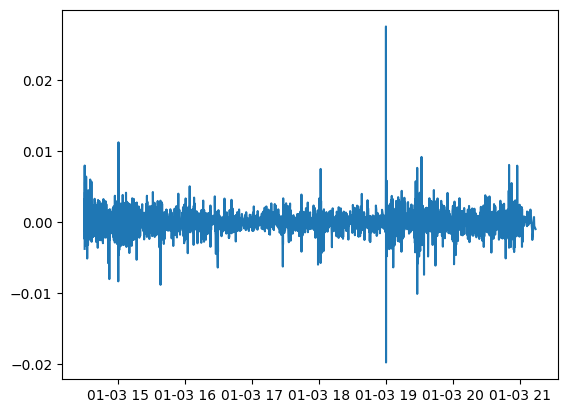

In [22]:
plt.plot(df_iv_trades_result["ts_ns"], df_iv_trades_result["trade_residual"])

In [23]:
plots.scatter_residual_vs_lag(df_iv_trades_result)

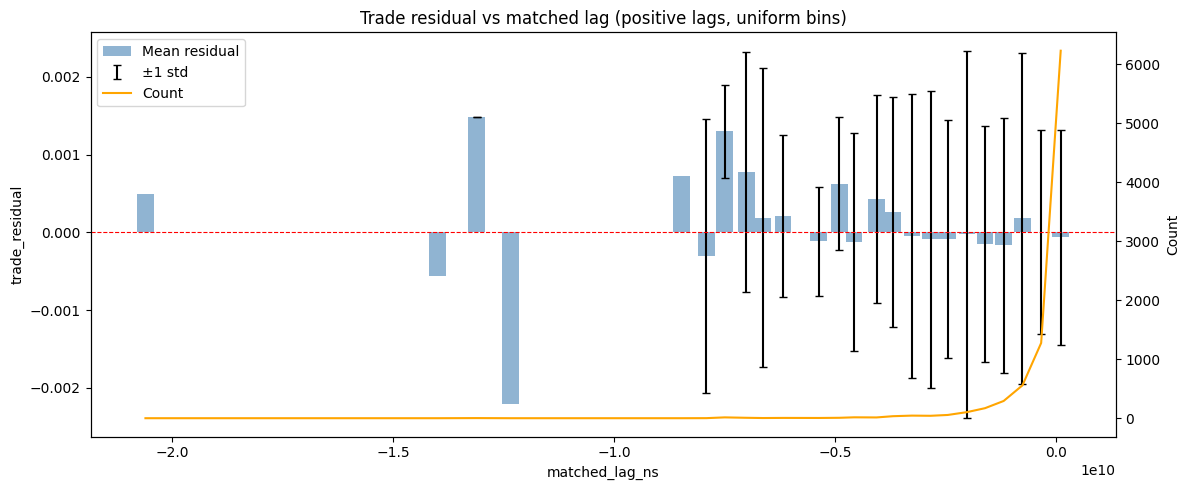

In [24]:
plots.plot_residual_vs_lag(df_iv_trades_result)

In [25]:
df_iv_trades_result.select((pl.col("trade_residual") ** 2).mean())

trade_residual
f64
0.000002


In [26]:
df_iv_trades_result.shape

(8895, 20)

In [27]:
df_iv_trades_result[["trade_residual", "observed_iv"]]

trade_residual,observed_iv
f64,f64
-0.00377,0.128063
-0.00094,0.130892
0.000014,0.130797
0.000674,0.131457
-0.000669,0.132718
…,…
-0.002507,0.303042
-0.002507,0.303042
0.000726,0.30424


In [28]:
def r_squared(observed: pl.Series, residuals: pl.Series) -> float:
    ss_res = (residuals**2).sum()
    ss_tot = ((observed - observed.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot


r2_price = r_squared(df_trades_result["observed_price"], df_trades_result["trade_residual"])
r2_iv = r_squared(df_iv_trades_result["observed_iv"], df_iv_trades_result["trade_residual"])

print(f"R² (price space): {r2_price:.4f}")
print(f"R² (IV space):    {r2_iv:.4f}")

R² (price space): 0.9988
R² (IV space):    0.9993


In [29]:
# plt.plot(df_iv_trades_result["ts_ns"], df_iv_trades_result["trade_residual"])

df_iv_trades_result.select((pl.col("trade_residual") ** 2).mean()) * 10000

trade_residual
f64
0.021495


## comparison

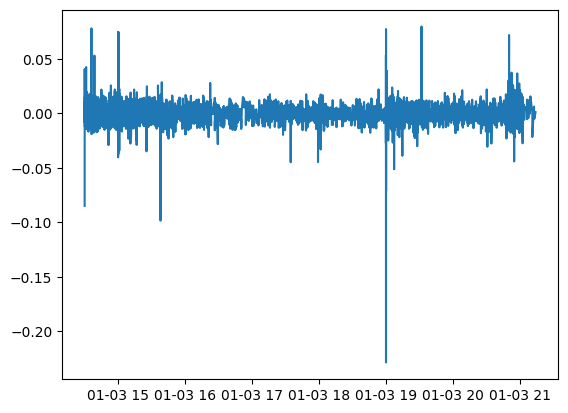

In [30]:
plt.plot(
    df_trades_result["ts_ns"],
    df_trades_result["trade_residual"] - df_iv_trades_result["trade_residual"],
)

In [31]:
diff = df_trades_result["trade_residual"] - df_iv_trades_result["trade_residual"]

In [32]:
diff.abs().mean()

0.006070802443261359

In [33]:
diff.abs().max()

0.22879199981689458

In [34]:
diff.shape

(8895,)

In [35]:
(diff.abs() > 0.0001).sum()

8801